In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
from tqdm import tqdm
import upsetplot

In [2]:
combined_df = pd.read_csv('../predictions/combined_preds/combined_no_sanjana_filtered_python.csv', index_col=0,
           # converters={
               # 'adhunter_centers' : ast.literal_eval, 
               #         'adhunter_preds' : ast.literal_eval,
               #         'tada_centers' : ast.literal_eval, 
               #        'tada_preds' : ast.literal_eval, 
               #         'adpred_preds' : ast.literal_eval, 
               #         'paddle_centers' : ast.literal_eval,
               #        'paddle_preds' : ast.literal_eval, 
               #         'adhunter_ensemble_centers' : ast.literal_eval, 
               #         'adhunter_ensemble_preds' : ast.literal_eval, 
               #        'adhunter_ensemble_uncertainty' : ast.literal_eval, 
               #         'combined_preds' : ast.literal_eval,
                      # 'adhunter_intervals' : ast.literal_eval, 
                      # 'tada_intervals' : ast.literal_eval, 
                      #  'adpred_intervals' : ast.literal_eval, 
                      #  'paddle_intervals' : ast.literal_eval, 
                      # 'adhunter_ensemble_intervals' : ast.literal_eval, 
                      #  'composition_intervals' : ast.literal_eval
           # }  
           )

In [3]:
combined_df

,name,sequence,adhunter_centers,adhunter_preds,tada_centers,tada_preds,adpred_preds,paddle_centers,paddle_preds,adhunter_ensemble_centers,adhunter_ensemble_preds,adhunter_ensemble_uncertainty,combined_preds,adhunter_intervals,tada_intervals,adpred_intervals,paddle_intervals,adhunter_ensemble_intervals
0,Aco021664.1,MELERQDKEEEEEEEEELLRTAAAVPMHRFIVPKPEPMELFGSLQL...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[23948.734,34398.383,34643.266,30163.777,46331...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.20640308,0.2299711,0.23149782,0.22729242,0....","[0.000457561,0.0005376012,0.00062079023,0.0016...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.15613313,0.1687365,0.17277826,0.17923725,0....","[27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,...","[-0.7733858227729797,-0.8443028330802917,-0.80...","[[,0,.,0,1,8,5,1,2,7,5,0,0,4,4,4,6,5,0,6,5,,, ...","[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0...",NaN,NaN,NaN,NaN,NaN
1,Aco014880.1,MGSPENPNWYLDCALIDELPVADGGLCWSAQGFNSSSNVSLETDGP...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[163864.33,166590.23,153676.1,149345.64,139923...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.617012,0.60880744,0.6142499,0.6240743,0.621...","[0.08309816,0.17942944,0.29228172,0.2683431,0....","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[7.2677155,7.249478,7.1840224,7.1038427,7.0258...","[27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,...","[0.41324320435523987,0.2205643206834793,0.3367...","[[,0,.,0,5,0,6,8,2,2,2,8,0,5,8,5,7,6,5,8,4,,, ...","[0.6,0.6,0.6,0.6,0.6,0.6,0.6,0.8,0.8,0.8,0.8,0...","[(0, 51)]","[(0, 53)]","[(7, 24)]","[(0, 66)]",NaN
2,Aco002151.1,MLLHPRSAFSTYARVGSHDIGSLAAGRHVGSAAAVNVHRRLFGFIR...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[40901.55,39849.902,44446.395,46577.89,48848.3...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.15860836,0.16032039,0.16562296,0.16951677,0...","[0.0013301629,0.001206241,0.0013138953,0.00109...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.052201796,-0.056321103,-0.05690101,-0.0570...","[27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,...","[-0.5648762583732605,-0.554851233959198,-0.579...","[[,0,.,0,1,4,0,2,0,3,9,5,4,6,5,1,9,5,1,7,9,,, ...","[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0...",NaN,NaN,NaN,NaN,NaN
3,Aco018224.1,MFVFENQSRDSSSPVSKQSNGRGFPSHLLLLLRLAAAAAAAAAAAA...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[52955.406,57674.707,60400.03,63605.56,59457.2...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.189424,0.18299682,0.17208093,0.16736288,0.1...","[0.0027180198,0.0023544286,0.0015037733,0.0013...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.034381293,-0.034525078,-0.033828054,-0.032...","[27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,...","[-0.8527296781539917,-0.8746128082275391,-0.93...","[[,0,.,0,1,0,5,2,5,4,0,8,2,0,0,9,1,9,6,2,8,,, ...","[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0...","[(395, 436)]","[(207, 260), (381, 448)]",NaN,"[(194, 261), (369, 449)]",NaN
4,Aco005374.1,MEFRSNQDDDMGLPSSLSYNNNNNNNNNNNNNNSSNNPLPIRGSAF...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[21428.078,23407.145,33649.83,28168.95,34537.4...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.19193147,0.19046147,0.17961264,0.1756722,0....","[0.0016205282,0.0021502455,0.004893229,0.00514...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.31436068,0.3567606,0.38733268,0.38166854,0....","[27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,...","[-0.958437442779541,-1.0686415433883667,-1.035...","[[,0,.,0,2,7,5,6,2,9,7,5,8,8,3,4,8,3,8,8,7,,, ...","[0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0...",NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Q1L604,MERQNGPVANCEVRIGDTNAFPFANSNRSHGLDQVAQVKILEANQQ...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[42824.598,47310.406,45304.836,42242.062,49439...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.17582999,0.18409999,0.19033362,

In [6]:
# combined_df = combined_df[['adhunter_intervals','tada_intervals', 'adpred_intervals', 'paddle_intervals', 'adhunter_ensemble_intervals', ]]

In [ ]:
# Question: 
# How many ADs are predicted by just one predictor vs. multiple

# For each row: 
# For each AD in the row: 
# How many of the predictors interact/which predictors predict them? 

# For each AD: 
# 1 if predicted by predictor, 0 if predicted no 

In [8]:
combined_df = combined_df.reset_index() #

In [9]:
combined_df.loc[3, 'adhunter_intervals']

'[(395, 436)]'

In [10]:
adhunter_intervals = [(395, 436)]	
tada_intervals = [(207, 260), (381, 448)]
adhunter_ensemble_intervals = [(194, 261), (369, 449)]	
adpred_intervals = np.nan

In [11]:
ad_ls = [adhunter_intervals, tada_intervals, adhunter_ensemble_intervals, adpred_intervals]
ad_ls

[[(395, 436)], [(207, 260), (381, 448)], [(194, 261), (369, 449)], nan]

In [12]:
# Goal: Make each AD its own row, and extract all things that it overlaps with 

# Row with (194, 261) and (207, 260) and rest na
# Row with (369, 449) and (381, 448) and (395, 436) and rest na

list(combined_df.loc[3,['adhunter_intervals', 'tada_intervals']].values)


['[(395, 436)]', '[(207, 260), (381, 448)]']

In [91]:
def merge_intervals(intervals):
    # Sort intervals by start position
    sorted_intervals = sorted(intervals)
    
    # Initialize merged list with the first interval
    merged = [sorted_intervals[0]]
    
    for start, end in sorted_intervals[1:]:
        # If current interval overlaps with the last merged interval
        if start <= merged[-1][1]:
            # Extend the last merged interval to the max end point
            merged[-1] = (merged[-1][0], max(merged[-1][1], end))
        else:
            # No overlap, add as a new separate interval
            merged.append((start, end))
    
    return merged
    
def get_ad_list(combined_df, i): 
    adhunter_ads = combined_df.loc[i,'adhunter_intervals']
    tada_ads = combined_df.loc[i,'tada_intervals']
    adpred_ads = combined_df.loc[i,'adpred_intervals']
    paddle_ads = combined_df.loc[i,'paddle_intervals']
    adhunter_ensemble_ads = combined_df.loc[i,'adhunter_ensemble_intervals']
    
    ads = [adhunter_ads, tada_ads, adpred_ads, paddle_ads, adhunter_ensemble_ads]
    flattened_ads = []
    
    for ad_ls in ads:
        if isinstance(ad_ls, str):
            ad_ls = ast.literal_eval(ad_ls)
            for start, end in ad_ls:
                flattened_ads.append((start, end))
                
    # Merge overlapping ADs, necessary for downstream stuff
    if len(flattened_ads) > 0:
        flattened_ads = merge_intervals(flattened_ads) 
    return flattened_ads
    

In [92]:
# This is the code to make each AD its own row
# Seqs that have ADs that overlap with an AD are marked with "True" while those that don't are marked with "False" 
# Ads that have already been accounted for via overlap are removed from our running list
# Merges overlapping ADs in the get_ad_list helper function - this just counts which predictors overlap with that largest boundary of an AD

# coords_to_move = {}
ad_df = pd.DataFrame()
for i in tqdm(combined_df.index): 
    ads = get_ad_list(combined_df, i)
    used_ads = []
    
    for start1, end1 in ads:
        if (start1, end1) not in used_ads: 
            coords_to_move = {'tada' : False, #np.nan, 
                         'adhunter' : False, #np.nan, 
                         'paddle' : False, #np.nan, 
                         'adpred' : False, #np.nan,
                         'adhunter_ensemble' : False} #np.nan}
            if isinstance(combined_df.loc[i, 'tada_intervals'], str): 
                for start2, end2 in ast.literal_eval(combined_df.loc[i, 'tada_intervals']): 
                    if ((start1 > start2) and (end1 > end2)) or ((start1 < start2) and (end1 < end2)):
                        continue
                    else: 
                        coords_to_move['tada'] = True #(start2, end2) 
                        used_ads.append((start2, end2)) 
            if isinstance(combined_df.loc[i, 'adhunter_intervals'], str): 
                for start2, end2 in ast.literal_eval(combined_df.loc[i, 'adhunter_intervals']): 
                    if ((start1 > start2) and (end1 > end2)) or ((start1 < start2) and (end1 < end2)):
                        continue
                    else:
                        coords_to_move['adhunter'] = True #(start2, end2) 
                        used_ads.append((start2, end2))
            if isinstance(combined_df.loc[i, 'paddle_intervals'], str): 
                for start2, end2 in ast.literal_eval(combined_df.loc[i, 'paddle_intervals']): 
                    if ((start1 > start2) and (end1 > end2)) or ((start1 < start2) and (end1 < end2)):
                        continue
                    else:
                        coords_to_move['paddle'] = True #(start2, end2) 
                        used_ads.append((start2, end2)) 
            if isinstance(combined_df.loc[i, 'adpred_intervals'], str): 
                for start2, end2 in ast.literal_eval(combined_df.loc[i, 'adpred_intervals']): 
                    if ((start1 > start2) and (end1 > end2)) or ((start1 < start2) and (end1 < end2)):
                        continue
                    else:
                        coords_to_move['adpred'] = True #(start2, end2) 
                        used_ads.append((start2, end2)) 
            if isinstance(combined_df.loc[i, 'adhunter_ensemble_intervals'], str): 
                for start2, end2 in ast.literal_eval(combined_df.loc[i, 'adhunter_ensemble_intervals']): 
                    if ((start1 > start2) and (end1 > end2)) or ((start1 < start2) and (end1 < end2)):
                        continue
                    else:
                        coords_to_move['adhunter_ensemble'] = True #(start2, end2) 
                        used_ads.append((start2, end2)) 
            
            row_of_df = pd.DataFrame([coords_to_move])
            ad_df = pd.concat([ad_df, row_of_df])

100%|██████████| 134655/134655 [01:51<00:00, 1203.90it/s]


In [93]:
ad_df = ad_df.reset_index(drop=True)
ad_df

,tada,adhunter,paddle,adpred,adhunter_ensemble
0,True,True,True,True,False
1,True,False,True,False,False
2,True,True,True,False,False
3,True,True,False,False,True
4,True,True,False,True,False
...,...,...,...,...,...
188243,True,False,False,False,False
188244,True,True,False,False,True
188245,True,True,True,True,True
188246,False,True,False,False,False


/global/scratch/users/claireleblanc/conda_environments/basic/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/global/scratch/users/claireleblanc/conda_environments/basic/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work be

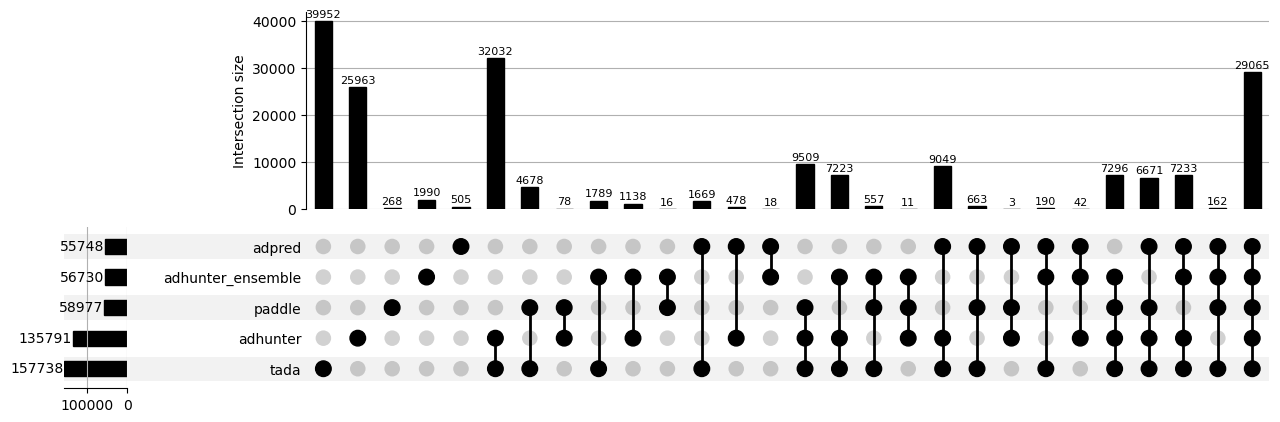

In [94]:
# I think this works! 

# Now, need to use upset plot to display the results
plotting_df = upsetplot.from_indicators(ad_df)
fig = upsetplot.plot(plotting_df, subset_size='count', show_counts=True)

for text in fig['intersections'].texts:
    text.set_fontsize(8)

In [61]:
# For each defined ad: add it to a list
# This works for two sets of ADs! 
# But not sure if it will work for more 

adhunter_ads = []
tada_ads = []

if isinstance(combined_df.loc[3, 'adhunter_intervals'], str): 
    for start1, end1 in adhunter_intervals:
        if isinstance(combined_df.loc[3, 'tada_intervals'], str): 
            for start2, end2 in tada_intervals: 
                if ((start1 > start2) and (end1 > end2)) or ((start1 < start2) and (end1 < end2)):
                    tada_ads.append(1)
                    adhunter_ads.append(0)
                else:
                    tada_ads.append(1)
                    adhunter_ads.append(1)
        else: 
            tada_ads.append(0)
            adhunter_ads.append(1)
            
        # if isinstance(combined_df.loc[3, 'tada_intervals'], str): 
        #     for start2, end2 in tada_intervals: 
        #         if ((start1 > start2) and (end1 > end2)) or ((start1 < start2) and (end1 < end2)):
        #              tada_ads.append(0)
        #         else:
        #             tada_ads.append(1)
        # else: 
        #     tada_ads.append(0)
    
adhunter_ads

[0, 1]

In [59]:
combined_df.loc[3, 'adhunter_intervals']

'[(395, 436)]'

In [62]:
combined_df.loc[3, 'tada_intervals']

'[(207, 260), (381, 448)]'

In [38]:
if isinstance(combined_df.loc[3, 'adhunter_intervals'], str):
    ads = ast.literal_eval(combined_df.loc[3, 'adhunter_intervals'])
    for ad in ads:
        adhunter_start = ad[0]
        adhunter_end = ad[1]
    

(395, 436)


In [40]:
combined_df[['adhunter_intervals','tada_intervals', 'adpred_intervals', 'paddle_intervals', 'adhunter_ensemble_intervals']]

,adhunter_intervals,tada_intervals,adpred_intervals,paddle_intervals,adhunter_ensemble_intervals
0,NaN,NaN,NaN,NaN,NaN
1,"[(0, 51)]","[(0, 53)]","[(7, 24)]","[(0, 66)]",NaN
2,NaN,NaN,NaN,NaN,NaN
3,"[(395, 436)]","[(207, 260), (381, 448)]",NaN,"[(194, 261), (369, 449)]",NaN
4,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
134650,"[(456, 516)]","[(307, 350), (447, 509)]",NaN,NaN,"[(454, 506)]"
134651,"[(151, 233)]","[(147, 233)]","[(204, 230)]","[(138, 234)]","[(172, 227)]"
134652,"[(21, 72)]",NaN,NaN,NaN,NaN
134653,NaN,NaN,NaN,NaN,NaN


In [20]:
# adhunter_ADs, tada_ADs, adpred_ADs, paddle_ADs, adhunter_ensemble_ADs = []
for i in tqdm(combined_df.index):
    for col in ['adhunter_intervals','tada_intervals', 'adpred_intervals', 'paddle_intervals', 'adhunter_ensemble_intervals', 'composition_intervals']:
        ads = combined_df.loc[i, col]
        

  0%|          | 0/134655 [00:00<?, ?it/s]

0                                                NaN
0                                       [(174, 221)]
0                             [(18, 60), (100, 184)]
0                                                NaN
0                           [(274, 326), (347, 393)]
                          ...                       
0                                        [(53, 134)]
0                    [(5, 45), (53, 93), (175, 224)]
0                             [(13, 64), (232, 292)]
0                                       [(524, 565)]
0    [(17, 135), (163, 254), (613, 673), (690, 734)]
Name: adhunter_intervals, Length: 134, dtype: object
0                                               NaN
0                                      [(149, 194)]
0                                      [(112, 183)]
0                                               NaN
0              [(129, 235), (285, 326), (347, 392)]
                          ...                      
0                                       [(81, 145)]


KeyError: 'composition_intervals'